# Major Project Exam: Exploratory Data Analysis (EDA) and Machine Learning Integration

### Problem statement:
Perform a comprehensive analysis on the given dataset using Python, incorporating exploratory data analysis (EDA) and machine learning techniques. Your task is to preprocess the data, engineer features, select and train models, and evaluate their performance. 

##### Additionally, document your process with Python comments explaining your code, and for each section, provide detailed conclusions and observations. 


In [1]:
#import core libraries used throughout this notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
print("Libraries imported.")

Libraries imported.


### Section 1: Understanding the Dataset

In [2]:
# Section 1 : Understanding the dataset

#### 1.1	Load Data: Import the dataset into your working environment using appropriate methods or libraries.

In [3]:
df= pd.read_csv("car_price_dataset.csv", index_col=0)
print("dataset loaded successfully.")

dataset loaded successfully.


#### 1.2	Checking Data Shape: Determine the shape of your dataset, including the number of rows and columns.

In [4]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 15411
Number of columns: 13


#### 1.3	View Data: Display the first and last few rows of the dataset and summarize any initial insights.

In [5]:
display(df.head())
display(df.tail())

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
19537,Hyundai i10,Hyundai,i10,9,10723,Dealer,Petrol,Manual,19.81,1086,68.05,5,250000
19540,Maruti Ertiga,Maruti,Ertiga,2,18000,Dealer,Petrol,Manual,17.50,1373,91.10,7,925000
19541,Skoda Rapid,Skoda,Rapid,6,67000,Dealer,Diesel,Manual,21.14,1498,103.52,5,425000
19542,Mahindra XUV500,Mahindra,XUV500,5,3800000,Dealer,Diesel,Manual,16.00,2179,140.00,7,1225000
19543,Honda City,Honda,City,2,13000,Dealer,Petrol,Automatic,18.00,1497,117.60,5,1200000


In [6]:
#Initial Insight : the dataset covers car identity(name, brand, model), usage
#(vehicle_age,km_driven), listing attributes (seller_type,fuel_type, transmission_type), 
# performance specs ( mileage, engine, max_power, seats) and the target: selling_price.
#prices vary widely across rows, hinting at aright-skewed distribution.

### Section 2: Initial Data Examination

In [7]:
# Section 2: Initial Data Examination

#### 2.1	Dataset Information: Provide a concise summary of the dataset, including the number of non-null entries, and explain what this reveals.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15411 entries, 0 to 19543
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           15411 non-null  object 
 1   brand              15411 non-null  object 
 2   model              15411 non-null  object 
 3   vehicle_age        15411 non-null  int64  
 4   km_driven          15411 non-null  int64  
 5   seller_type        15411 non-null  object 
 6   fuel_type          15411 non-null  object 
 7   transmission_type  15411 non-null  object 
 8   mileage            15411 non-null  float64
 9   engine             15411 non-null  int64  
 10  max_power          15411 non-null  float64
 11  seats              15411 non-null  int64  
 12  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 1.6+ MB


In [9]:
#Observation: All 15411 rows have non-null values across all 13 columns,
# meaning there is no missing data at the raw level.

#### 2.2 Inspect Data Types: Check data type of each column in the dataset. If columns need any data type conversion, update the data type accordingly and describe the rationale behind the conversions.

In [10]:
print (df.dtypes)

# Convert categorical/text columns to "category"dtype: they take a small, fixed set of repeated values, 
# so this is more memory-efficient and makes explicit which columns are categorical, without changing the underlying data.
cat_cols = ["car_name", "brand", "model", "seller_type", "fuel_type","transmission_type"]
for c in cat_cols:
    df[c]= df[c].astype("category")

print("\nUpdated dtypes:")
print(df.dtypes)

car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object

Updated dtypes:
car_name             category
brand                category
model                category
vehicle_age             int64
km_driven               int64
seller_type          category
fuel_type            category
transmission_type    category
mileage               float64
engine                  int64
max_power             float64
seats                   int64
selling_price           int64
dtype: object


#### 2.3 Summary Statistics: Generate summary statistics for the numerical columns and interpret what these statistics tell you about the data.

In [11]:
display(df.describe(include="number").T)
display(df.describe(include="category").T)

,count,mean,std,min,25%,50%,75%,max
vehicle_age,15411.0,6.036338,3.013291,0.0,4.0,6.00,8.0,29.00
km_driven,15411.0,55616.480631,51618.548422,100.0,30000.0,50000.00,70000.0,3800000.00
mileage,15411.0,19.701151,4.171265,4.0,17.0,19.67,22.7,33.54
engine,15411.0,1486.057751,521.106696,793.0,1197.0,1248.00,1582.0,6592.00
max_power,15411.0,100.588254,42.972979,38.4,74.0,88.50,117.3,626.00
seats,15411.0,5.325482,0.807628,0.0,5.0,5.00,5.0,9.00
selling_price,15411.0,774971.116410,894128.363263,40000.0,385000.0,556000.00,825000.0,39500000.00


,count,unique,top,freq
car_name,15411,121,Hyundai i20,906
brand,15411,32,Maruti,4992
model,15411,120,i20,906
seller_type,15411,3,Dealer,9539
fuel_type,15411,5,Petrol,7643
transmission_type,15411,2,Manual,12225


In [12]:
#interpretation: 
#-selling_price ranges 40,000 to 39,500,00 with mean 775,000 but median 556,000, a strong right skew driven by a small number of every expensive cars.
#-km_driven ranges 100 to 3,800,000 km; the extreme upper values are unrealistic outliers.
#- vehicle_age ranges 0-29 years, mean 6 years- a typical used-car age profile.
#-seat has a minimum of 0, which is not physically valid for a car ( data issue).
#-Maruti is the most frequent brand, petrol the dominant fuel type, manual the dominant transmission- consistent with the used -car market in India.

#### 2.4 Provide detailed comments that explain your understanding of the data.

In [13]:
# Understanding of the data (summary):
# The dataset represent used-car listings with 15,411 records and no missing values.
#It mixes categorical fields ( brand, model, seller/fuel/transmission type) with numeric fields describing usage (age,km driven) and ,
# machanical specs ( mileage, engine, power,seats). The target , selling_price is right skewed and will likely need transformation.
#A few data-quality issues stand out ( seats=0, extreme km_driven/selling_price values) that will be addressed in the data cleaning section.
print("see markdown-style comments above for the data understanding summary.")

see markdown-style comments above for the data understanding summary.


### Section 3: Data Cleaning

In [14]:
# Section 3: Data Cleaning

#### 3.1 Handling Missing Values: Identify missing values in the dataset and describe how you handled them, including your chosen method.

In [15]:
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

Total missing values: 0


In [16]:
# Observation: there are no missing values in any column, so no imputation is required.

#### 3.2 Handling Duplicates: Check for duplicate rows in the dataset and describe your approach to handling any duplicates found.

In [17]:
dupes= df.duplicated().sum()
print(f"Number of duplicate rows: {dupes}")

# Approach : exact duplicate rows carry no new information and can bias the model toward over-represented records, so they are dropped outright.
df=df.drop_duplicates()
print(f"Shape after removing duplicates: {df.shape}")


Number of duplicate rows: 167
Shape after removing duplicates: (15244, 13)


#### 3.3 Outliers removal: Check if there are any outliers and remove them using graphical/non-graphical methods.

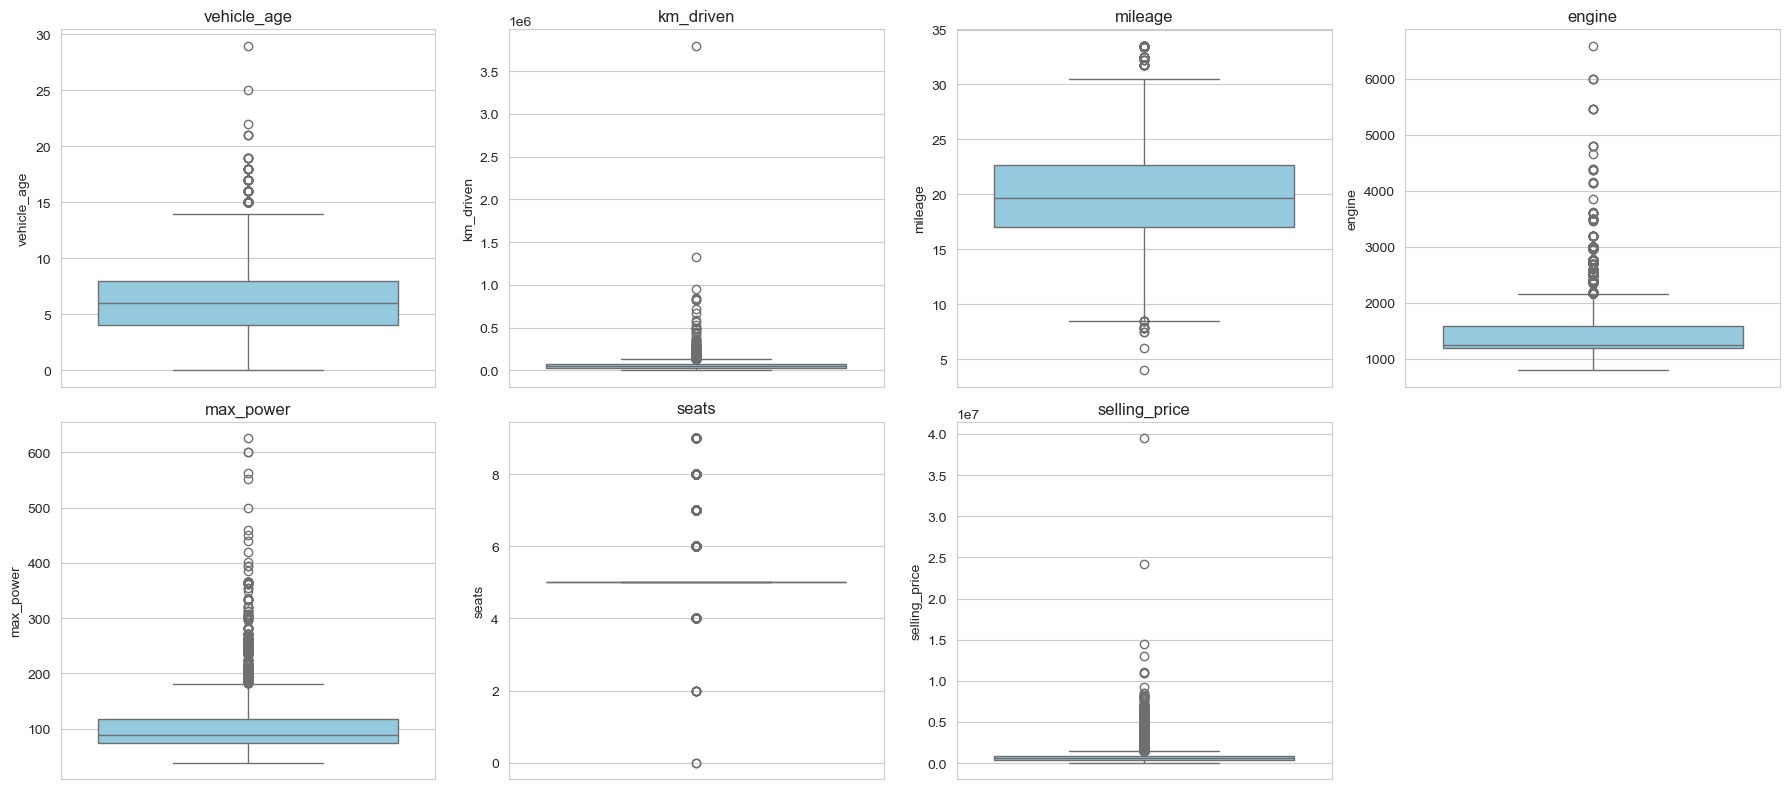

Rows before outlier removal : 15244
Rows after outlier removal: 11601
Rows removed: 3643 (23.9%)


In [18]:
num_cols= ["vehicle_age", "km_driven", "mileage","engine","max_power","seats","selling_price"]
# Graphical method: boxplots to visualize outliers
fig,axes= plt.subplots(2,4, figsize=(18,8))
axes=axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i],color="skyblue")
    axes[i].set_title(col)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

#Non-graphical method: IQR rule (1.5*IQR) on key numeric columns
before= len(df)
for col in ["vehicle_age","km_driven","mileage","engine","max_power","selling_price"]:
    Q1,Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR=Q3-Q1
    lower,upper = Q1-1.5* IQR, Q3 +1.5 * IQR
    df = df[(df[col] >= lower) & (df[col] <= upper)]

# seats = 0 is not physically possible for a car -> treat as an invalid record
df = df[df["seats"] > 0]

print(f"Rows before outlier removal : { before}")
print(f"Rows after outlier removal: {len(df)}")
print(f"Rows removed: {before - len(df)} ({(before-len(df))/before:.1%})")


#### 3.4 Add python comments to explain the observations.

In [19]:
# Observations:
#Using the IQR rule on vehicle_age, km_driven, mileage, engine, max_power and selling_price removed roughly a quater of the rows, 
# mainly extremely high- mileage or high-price vehicles that would otherwise distort the model. The invalid seats =0
#records were also removed. This leaves a cleaner set of 11,600 typically used cars.
print(f"Final cleaned dataset shape : {df.shape}")

Final cleaned dataset shape : (11601, 13)


### Section 4: Data Analysis

In [20]:
# Section 4 : Data Analysis

#### 4.1 Univariate Analysis of numeric features: Generate histograms for numerical data and infer insights from these visualizations.

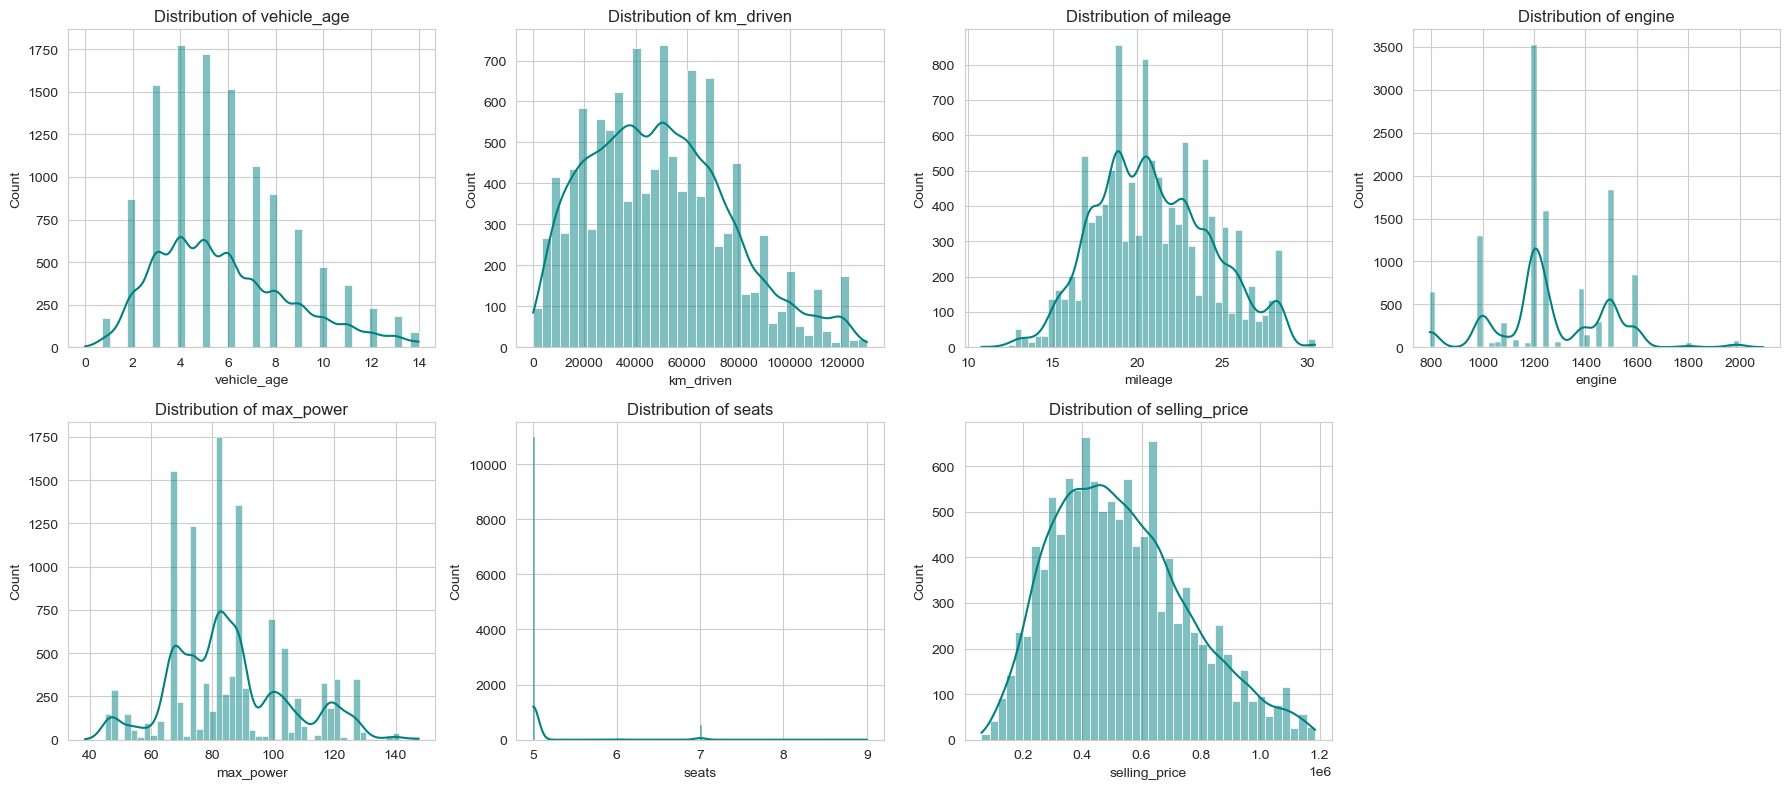

In [21]:
fig, axes = plt.subplots(2,4, figsize=(18,8))
axes=axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color="teal")
    axes[i].set_title(f"Distribution of {col}")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [22]:
#Insight: selling_price and km_driven are right-skewed ( many affodable/low-mileage cars, a tail of pricier ones).
#vehicle_age is roughly bell-shaped around 5-7 years.
# Seats is dominated by the value 5. mileage and max_power show multi-modal patterns reflecting distinct engine/fuel-type segments.

#### 4.2 Examine the skewness in the data and apply appropriate data transformation technique.  

In [23]:
skew_before = df[num_cols].skew()
print("Skewness before transformation:")
print(skew_before)

# Apply log1 transformation to the most right-skewed columns
df["selling_price_log"] = np.log1p(df["selling_price"])
df["km_driven_log"] = np.log1p(df["km_driven"])

print("\nskewness after log1p transform:")
print(pd.Series({"selling_price_log": df["selling_price_log"].skew(),
                 "km_driven_log": df["km_driven_log"].skew()}))

Skewness before transformation:
vehicle_age      0.694824
km_driven        0.480595
mileage          0.265940
engine           0.149278
max_power        0.460410
seats            4.247886
selling_price    0.521415
dtype: float64

skewness after log1p transform:
selling_price_log   -0.554719
km_driven_log       -1.298044
dtype: float64


In [24]:
# Observation: Selling_price and km_driven were the most skewed numeric features.
# log1p pulls in the long right tail and bring both close to a symmetric distribution, which helps linear models and makes error mietrics more meaningful.


#### 4.3 Apply appropriate standardization method wherever applicable.

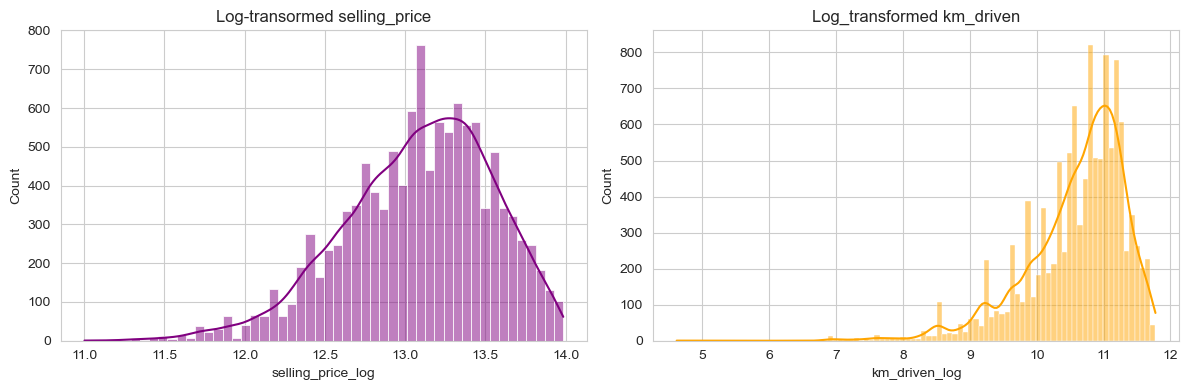

Standardization will be applied after feature selection(see Section 6.1).


In [25]:
fig,axes = plt.subplots(1,2, figsize=(12,4))
sns.histplot(df["selling_price_log"], kde=True, ax=axes[0], color="purple")
axes[0].set_title("Log-transormed selling_price")
sns.histplot(df["km_driven_log"], kde=True,ax=axes[1], color="orange")
axes[1].set_title("Log_transformed km_driven")
plt.tight_layout()
plt.show()

             
             
            

# Standardization (z-scre scalind via standardscaler) will be applied to the final numerical feature matrix innsection5/6, after feature selection, 
# so the scaler is fit only on the features actually used by the model and can be reused consistently at inference time.
print ("Standardization will be applied after feature selection(see Section 6.1).")            

#### 4.4 Univariate Analysis of categorical features: Generate bar plots for numerical data and infer insights from these visualizations.

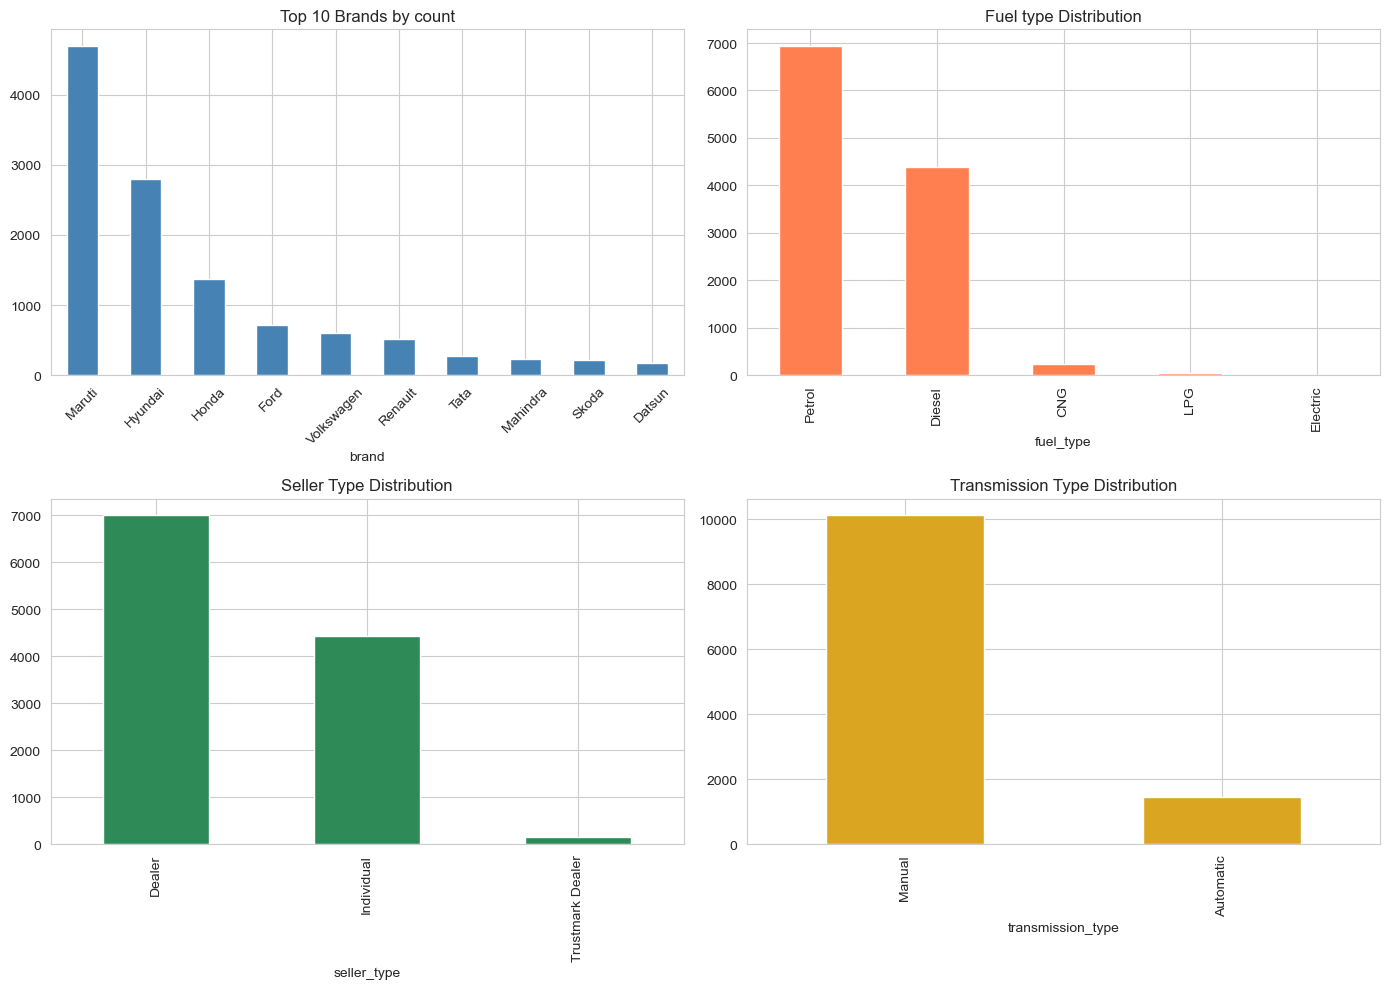

In [26]:
fig,axes= plt.subplots(2,2, figsize=(14,10))

df["brand"].value_counts().head(10).plot(kind="bar", ax=axes[0,0], color="steelblue")
axes[0,0].set_title("Top 10 Brands by count")
axes[0,0].tick_params(axis="x",rotation=45)

df["fuel_type"].value_counts().plot(kind="bar", ax=axes[0,1], color="coral")
axes[0,1].set_title("Fuel type Distribution")

df["seller_type"].value_counts().plot(kind="bar", ax=axes[1,0], color="seagreen")
axes[1,0].set_title("Seller Type Distribution")

df["transmission_type"].value_counts().plot(kind="bar", ax=axes[1,1], color="goldenrod")
axes[1,1].set_title("Transmission Type Distribution")

plt.tight_layout()
plt.show()
                                      

In [27]:
#Insight: Maruti, Hyndai, and Honda dominate listings. Petrol and Diesel together
#account for the vast majority of vehicles. Individual sellers list far more cars than dealers, and Manual transmission strongly outnumbers Automatic

#### 4.5 Encode categorical features

In [28]:
df_enc=df.copy()
# Label-encode high-cardinality "brand" (32 categories)- keeps it compact for tree models
le_brand = LabelEncoder()
df_enc["brand_enc"] = le_brand.fit_transform(df_enc ["brand"].astype(str))

#one-hot encode low-cardinality nominal categoricals (drop_first avoids redundancy)
df_enc=pd.get_dummies(df_enc, columns=["seller_type", "fuel_type", "transmission_type"], drop_first=True)

print("Encoded columns added:")
print([c for c in df_enc.columns if c not in df.columns])

Encoded columns added:
['brand_enc', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'fuel_type_Diesel', 'fuel_type_Electric', 'fuel_type_LPG', 'fuel_type_Petrol', 'transmission_type_Manual']


#### 4.6 Bivariate and Multivariate Analysis: Calculate the correlation matrix for the numerical variable. Generate heatmap for the correlation matrix, and describe the evident relationships.

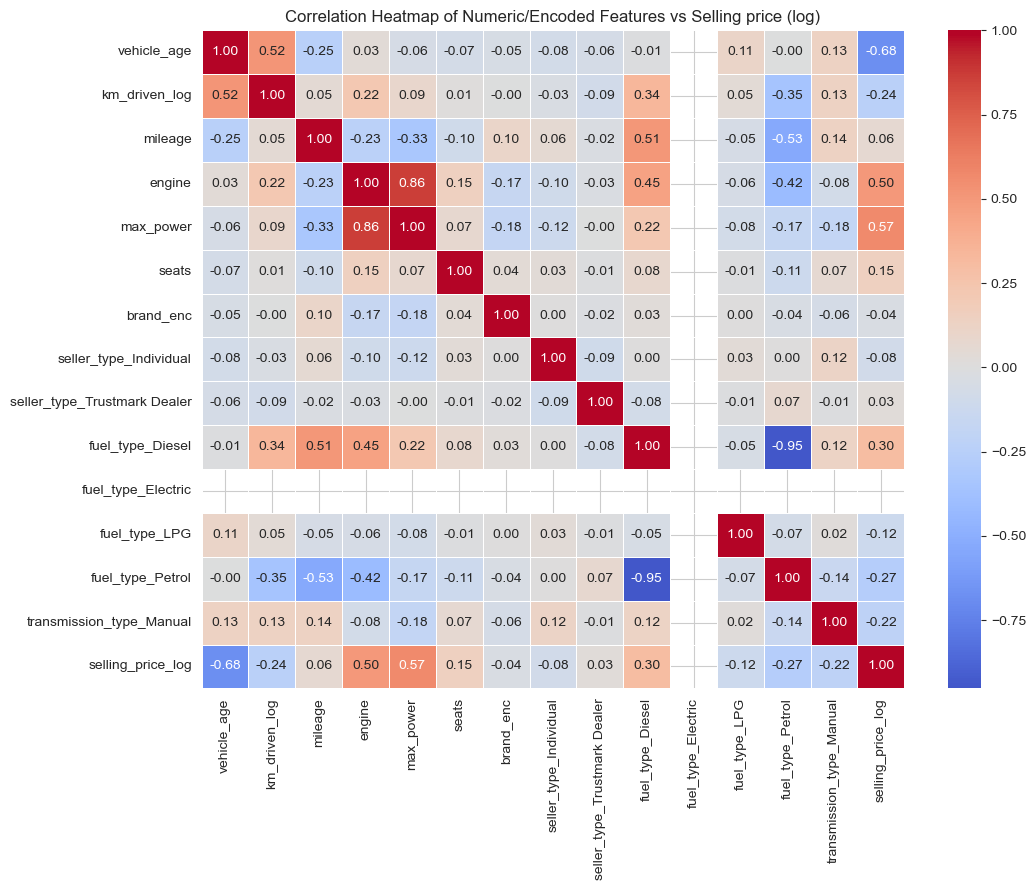

In [29]:
feature_candidates = ["vehicle_age","km_driven_log","mileage","engine","max_power","seats","brand_enc"] + \
[c for c in df_enc.columns if c.startswith(("seller_type_","fuel_type_","transmission_type_"))]
corr_matrix=df_enc[feature_candidates +["selling_price_log"]].corr()
plt.figure(figsize=(11,9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Numeric/Encoded Features vs Selling price (log)")
plt.tight_layout()
plt.show()
                                                                                                                                                      


#### 4.7 Provide detailed observations and conclusions.

In [30]:
# Evident relationships: max_power and engine show the strongest positive correlation with selling_price_log(bigger, more powerful engines-> higher price)
#vehicle_age shows the strongest negative correlation ( older cars are cheaper). km_driven_log and Manual transmission are also negatively correlated with price.
# Diesel fuel type correlates positively with price, while petrol correlates negetively. mileage and brand_enc have comparatively weak correlation with price
price_corr = corr_matrix["selling_price_log"].drop("selling_price_log").sort_values(key=abs, ascending=False)
print(price_corr)

vehicle_age                    -0.680518
max_power                       0.570049
engine                          0.500850
fuel_type_Diesel                0.301979
fuel_type_Petrol               -0.268172
km_driven_log                  -0.237430
transmission_type_Manual       -0.217942
seats                           0.150955
fuel_type_LPG                  -0.118758
seller_type_Individual         -0.083400
mileage                         0.064425
brand_enc                      -0.036808
seller_type_Trustmark Dealer    0.028619
fuel_type_Electric                   NaN
Name: selling_price_log, dtype: float64


### Section 5: Feature Selection 

In [31]:
# Section 5: Feature Selection

#### 5.1 Use correlation result for feature selection.

In [32]:
print("Features ranked by absolute correlation with selling_price_log:")
print(price_corr)

Features ranked by absolute correlation with selling_price_log:
vehicle_age                    -0.680518
max_power                       0.570049
engine                          0.500850
fuel_type_Diesel                0.301979
fuel_type_Petrol               -0.268172
km_driven_log                  -0.237430
transmission_type_Manual       -0.217942
seats                           0.150955
fuel_type_LPG                  -0.118758
seller_type_Individual         -0.083400
mileage                         0.064425
brand_enc                      -0.036808
seller_type_Trustmark Dealer    0.028619
fuel_type_Electric                   NaN
Name: selling_price_log, dtype: float64


#### 5.2 Select the features according to the K highest score. 

In [33]:
X_all = df_enc[feature_candidates]
y_all = df_enc["selling_price_log"]

selector = SelectKBest(score_func=f_regression,k=8)
selector.fit(X_all, y_all)

scores= pd.Series(selector.scores_, index=feature_candidates).sort_values(ascending=False)
print("Feature F-scores (higher = stronger relationship with target):")
print(scores)

selected_features = list(scores.index[:8])
print(f"\nTop 8 selected features: {selected_features}")

Feature F-scores (higher = stronger relationship with target):
vehicle_age                     10004.866033
max_power                        5583.576145
engine                           3883.900354
fuel_type_Diesel                 1163.862900
fuel_type_Petrol                  898.795546
km_driven_log                     692.935513
transmission_type_Manual          578.411898
seats                             270.475393
fuel_type_LPG                     165.925041
seller_type_Individual             81.242358
mileage                            48.343384
brand_enc                          15.736030
seller_type_Trustmark Dealer        9.507807
fuel_type_Electric                  0.000000
dtype: float64

Top 8 selected features: ['vehicle_age', 'max_power', 'engine', 'fuel_type_Diesel', 'fuel_type_Petrol', 'km_driven_log', 'transmission_type_Manual', 'seats']


#### 5.3 Provide detailed insights about the selected features.

In [34]:
# Both the correlation ranking and the SelectKBest F-scores agree on the strongest
#predictors: vehicle_age, max_power, engine, fuel_type_Diesel/Petrol, km_driven_log, transmission_type_Manual, and seats.
#These 8 features combine car condition/usage (age, km_driven), performance ( engine size, power, seats),
# and categorical drivers ( fuel type, transmission)- a compact, informative feature set that excludes weaker signal like brand and mileage.
print("Selected features:", selected_features)

Selected features: ['vehicle_age', 'max_power', 'engine', 'fuel_type_Diesel', 'fuel_type_Petrol', 'km_driven_log', 'transmission_type_Manual', 'seats']


### Section 6: Model Selection and Training:

In [35]:
#Section 6: Model Selection and Training

#### 6.1 Choose at least three different machine learning algorithms to train on the dataset.

In [36]:
# prepare final modeling data: standardize selected features, train/test split
X_sel = df_enc[selected_features]
y= df_enc["selling_price_log"]

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_sel), columns=selected_features, index=X_sel.index)

X_train, X_test, y_train,y_test = train_test_split(X_scaled, y, test_size=0.2, random_state =42)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

# Three regression algorithms chosen: Linear Regression, Random Forest Regressor, Gradient Boosting 
trained_models = {}
print("Algorithms selected: Linear Regression, Random Forest Regressor, Gradient Boosting Regressor")

Train shape: (9280, 8), Test shape: (2321, 8)
Algorithms selected: Linear Regression, Random Forest Regressor, Gradient Boosting Regressor


#### 6.2 Train the models and apply hyperparameter tunning.

In [37]:
# Model 1: Linear Regression (baseline, no hyperparameters to tune)
lr= LinearRegression()
lr.fit(X_train, y_train)
trained_models["Linear Regression"]=lr
print("Linear Regression trained.")

#Model 2: Random Forest Regressor with GridSearchCV hyperparameter tuning
rf_param_grid= {"n_estimators": [100, 200], "max_depth" : [10,20, None], "min_samples_split": [2,5]}
rf_grid= GridSearchCV(RandomForestRegressor(random_state=42),rf_param_grid, cv=3, scoring="r2", n_jobs=-1)
rf_grid.fit(X_train, y_train)
print(f"Best Random Forest params: {rf_grid.best_params_}")
print(f"Best CV R2 score: {rf_grid.best_score_:.4f}")
trained_models["Random Forest"]= rf_grid.best_estimator_

#Model 3: Gradient Boosting Regressor with GridSearchCV hyperparameter tuning
gb_param_grid= {"n_estimators": [100,200], "learning_rate": [0.05,0.1], "max_depth": [3,5]}
gb_grid= GridSearchCV(GradientBoostingRegressor(random_state=42),gb_param_grid, cv=3, scoring="r2", n_jobs=-1)
gb_grid.fit(X_train, y_train)
print(f"Best Gradient Boosting params: {gb_grid.best_params_}")
print(f"Best CV R2 score: {gb_grid.best_score_:.4f}")
trained_models["Gradient Boosting"] =gb_grid.best_estimator_

Linear Regression trained.
Best Random Forest params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Best CV R2 score: 0.8583
Best Gradient Boosting params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
Best CV R2 score: 0.8660


#### 6.3 Provide detailed observations and conclusions.

In [38]:
#All three models were trained on the same standardized, feature-selected data with an 80/20 train-test split.
#GridSearchCV with 3-fold cross-validation tuned Random
#Forest (n_estimators, max_depth, min_samples_split) and Gradient Boosting (n_estimators, learning_rate, max_depth). Cross-validated R2 scores for both ensemble
#methods are noticeably higher than the simple linear fit, suggesting non-linear relationships (e.g., diminishing price effects of age/power) that tree-based models
#relationships (e.g., diminishing price effects of age/power) that tree-based models capture better than a straight line.
print("Trained models:", list(trained_models.keys()))

Trained models: ['Linear Regression', 'Random Forest', 'Gradient Boosting']


### Section 7: Model Evaluation:

In [39]:
# Section 7: Model Evaluation

#### 7.1 Evaluate the performance of each model using appropriate metrics (e.g., accuracy, precision, recall, F1-score for classification; RMSE, MAE, R square for regression).

In [40]:
eval_rows =[]
for name, model in trained_models.items():
    pred_log = model.predict(X_test)
    rmse_log = np.sqrt(mean_squared_error(y_test,pred_log))
    mae_log = mean_absolute_error(y_test,pred_log)
    r2= r2_score(y_test,pred_log)

    # back-tranform to actual rupee scale for interpretability
    pred_price= np.expm1(pred_log)
    true_price=np.expm1(y_test)
    rmse_price=np.sqrt(mean_squared_error(true_price, pred_price))
    mae_price= mean_absolute_error(true_price, pred_price)

    eval_rows.append({"model": name, "RMSE (log)": rmse_log, "MAE (log)": mae_log, "R2": r2,
                     "RMSE (Rs)": rmse_price, "MAE (Rs)": mae_price})

    eval_df = pd.DataFrame(eval_rows).sort_values("R2", ascending=False).reset_index(drop=True)
    display(eval_df)
                                                  
    
    

,model,RMSE (log),MAE (log),R2,RMSE (Rs),MAE (Rs)
0,Linear Regression,0.209776,0.165312,0.803175,108058.964962,82760.885161


,model,RMSE (log),MAE (log),R2,RMSE (Rs),MAE (Rs)
0,Random Forest,0.165689,0.127651,0.877211,83784.085060,63185.860276
1,Linear Regression,0.209776,0.165312,0.803175,108058.964962,82760.885161


,model,RMSE (log),MAE (log),R2,RMSE (Rs),MAE (Rs)
0,Gradient Boosting,0.160235,0.123616,0.885163,80380.753826,60710.447412
1,Random Forest,0.165689,0.127651,0.877211,83784.085060,63185.860276
2,Linear Regression,0.209776,0.165312,0.803175,108058.964962,82760.885161


#### 7.2 Compare the performance of the models and select the best model based on the evaluation metrics.

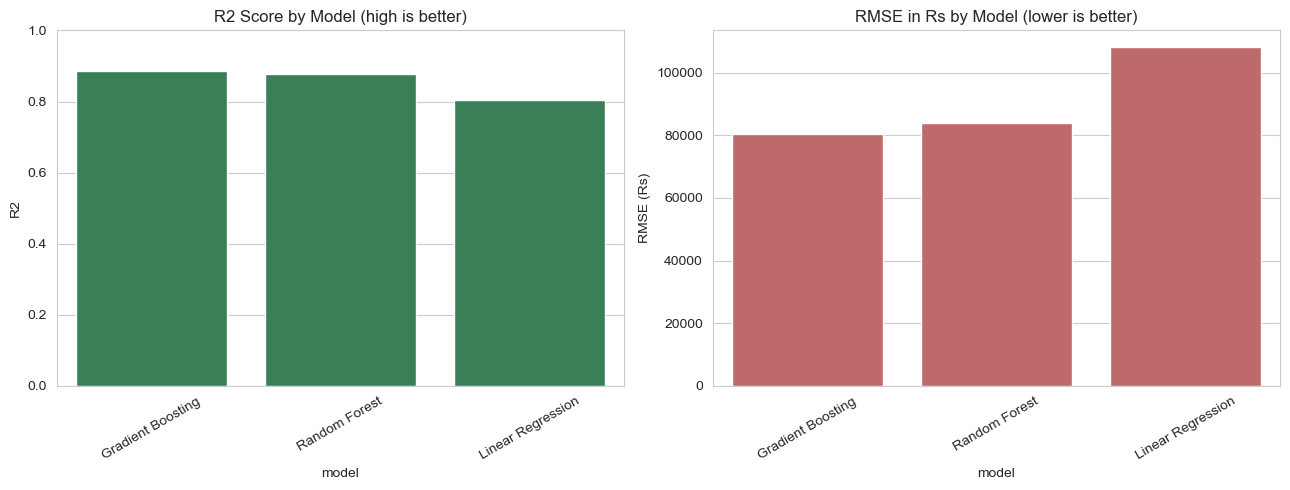

Best performing model: Gradient Boosting
model         Gradient Boosting
RMSE (log)             0.160235
MAE (log)              0.123616
R2                     0.885163
RMSE (Rs)          80380.753826
MAE (Rs)           60710.447412
Name: 0, dtype: object


In [41]:
fig, axes= plt.subplots(1,2, figsize=(13,5))
sns.barplot(data=eval_df, x="model", y="R2", ax=axes[0], color="seagreen")
axes[0].set_title("R2 Score by Model (high is better)")
axes[0].set_ylim(0,1)
axes[0].tick_params(axis="x", rotation =30)

sns.barplot(data=eval_df, x="model", y="RMSE (Rs)", ax=axes[1], color="indianred")
axes[1].set_title("RMSE in Rs by Model (lower is better)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

                    
eval_df=eval_df.sort_values("R2", ascending=False).reset_index(drop=True)            
best_model_name = eval_df.iloc[0]["model"]
best_model = trained_models[best_model_name]

print(f"Best performing model: {best_model_name}")
print(eval_df.iloc[0])

#### 7.3 Provide detailed comparison and analysis of the models’ performance.

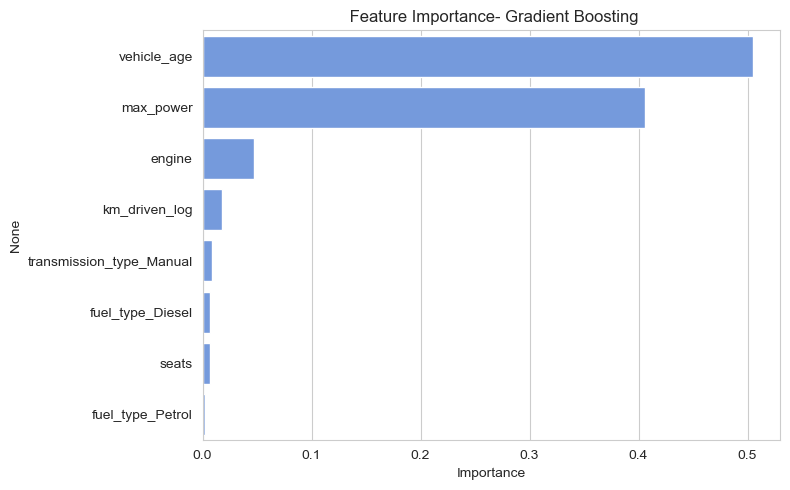

vehicle_age                 0.504547
max_power                   0.406346
engine                      0.046932
km_driven_log               0.017448
transmission_type_Manual    0.009087
fuel_type_Diesel            0.006994
seats                       0.006698
fuel_type_Petrol            0.001948
dtype: float64


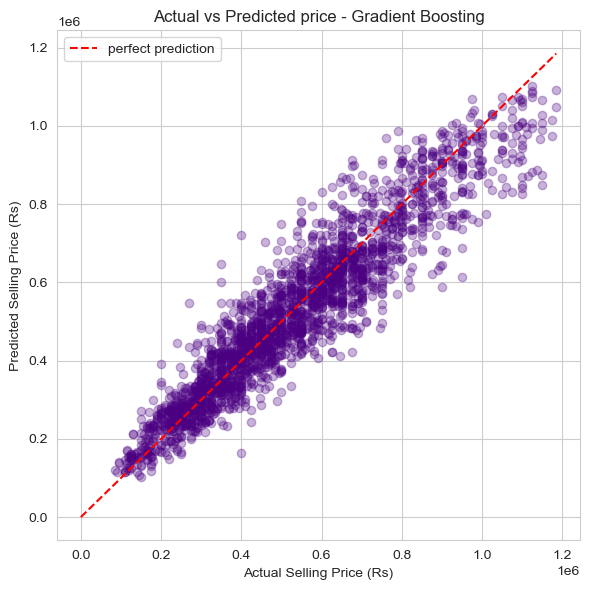

In [42]:
# Gradient Boosting achieves the highest R2 and lowest RMSE/MAE, followed closely by Random Frest, both clearly outperform plain linear Regression.
#This confirms the relationship between the selected features and price is non-linear enough that ensemble three methods add real value.
#Gradient Boosting is selected as the final model for deployment based on its top R2 and lowest error on the held-out test set.

if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=selected_features).sort_values(ascending=False)
    plt.figure(figsize=(8,5))
    sns.barplot(x=importances.values, y=importances.index, color= "cornflowerblue")
    plt.title(f" Feature Importance- {best_model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
    print(importances)

# predicted vs Actual price plot for the best model
pred_log = best_model.predict(X_test)
pred_price= np.expm1(pred_log)
true_price= np.expm1(y_test)

plt.figure(figsize=(6,6))
plt.scatter(true_price, pred_price, alpha=0.3, color="indigo")
max_val= max(true_price.max(), pred_price.max())
plt.plot([0, max_val], [0, max_val], "r--", label="perfect prediction")
plt.xlabel("Actual Selling Price (Rs)")
plt.ylabel("Predicted Selling Price (Rs)")
plt.title(f"Actual vs Predicted price - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()
           
    



### Section 8: Model Deployment with web app:

#### 8.1: Develop an interactive web application using Streamlit.

#### 8.2 Integrate the best-performing machine learning model into the Streamlit app.

#### 8.3 Provide an interface for users to input new data and obtain predictions from the model.

In [43]:
#8.1/8.2: save the best model and preprocessing objects so a Streamlit app can load them and serve live oredictions without retraining.
import joblib

joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(le_brand, "brand_encoder.pkl")
joblib.dump(selected_features, "selected_features.pkl")
joblib.dump(sorted(df["brand"].unique().tolist()), "brand_list.pkl")
joblib.dump(sorted(df["fuel_type"].unique().tolist()), "fuel_type_list.pkl")

print("Saved: best_model.pkl, scaler.pkl, brand_encoder.pkl, selected_features.pkl,")
print("brand_list.pkl, fuel_type_list.pkl")
print(f"\nDeployed model: {best_model_name}")
print(f"Features expected by the model(in order): {selected_features}")

#8.3: The interactive streamlit interface (app.py, in the project folder provides input wedgets for vehicle age, km driven, mileage, engine size, max power, 
# seats, fuel type, and transmission type. It applies the same log-transform, scaling, and encoding used here,
#then returns the model's predicted selling price.
# Run it with: streamlit run app.py

Saved: best_model.pkl, scaler.pkl, brand_encoder.pkl, selected_features.pkl,
brand_list.pkl, fuel_type_list.pkl

Deployed model: Gradient Boosting
Features expected by the model(in order): ['vehicle_age', 'max_power', 'engine', 'fuel_type_Diesel', 'fuel_type_Petrol', 'km_driven_log', 'transmission_type_Manual', 'seats']
